# 03 · Market-neutral long/short: summary

*Independent research project. Not affiliated with, endorsed by or produced for any current,
previous or future employer of the author. Public data only. Not investment advice.*

**Question.** Can a market-neutral book of listed shipping equities earn returns from stock
selection, rather than from the direction of freight rates or the market? And if so, where
does the information edge actually come from?

In [1]:
import json, warnings
import pandas as pd, matplotlib.pyplot as plt
from IPython.display import Markdown, display
from shiplab import charts
from shiplab.config import DATA
warnings.filterwarnings("ignore")
pd.set_option("display.precision", 3, "display.width", 140)
R = DATA / "results"
perf = pd.read_csv(R / "performance_by_period.csv")
strat = pd.read_parquet(R / "strategy_returns.parquet")
bench = pd.read_parquet(R / "benchmark_returns.parquet")
dsr = json.load(open(R / "deflated_sharpe.json"))
def row(period, series="Strategy"):
    return perf[(perf.period == period) & (perf.series == series)].iloc[0]

In [2]:
w, v, h = row("Walk-forward 2014-2020"), row("Validation 2021-2022"), row("Holdout 2023-")
fmt = lambda r: f"| {r.sharpe:.2f} | {r.ann_return:.1%} | {r.ann_vol:.1%} | {r.max_drawdown:.1%} | {r.beta:.2f} |"
p = dsr["deflated_sharpe_probability"]["Holdout 2023-"]
display(Markdown(
    "| Period | Sharpe | Annual return | Volatility | Max drawdown | Beta to S&P 500 |\n"
    "|---|---|---|---|---|---|\n"
    f"| Walk-forward 2014-2020 {fmt(w)}\n"
    f"| Validation 2021-2022 {fmt(v)}\n"
    f"| **Sealed holdout 2023-** {fmt(h)}\n\n"
    f"Deflated-Sharpe probability on the holdout after **{dsr['n_research_trials']} logged trials**: "
    f"**{p:.2f}**. Values above 0.95 would indicate skill with conventional confidence."))

| Period | Sharpe | Annual return | Volatility | Max drawdown | Beta to S&P 500 |
|---|---|---|---|---|---|
| Walk-forward 2014-2020 | 0.70 | 3.6% | 5.2% | -7.5% | 0.03 |
| Validation 2021-2022 | 0.61 | 3.3% | 5.5% | -5.1% | 0.01 |
| **Sealed holdout 2023-** | 0.42 | 2.1% | 5.3% | -7.2% | -0.01 |

Deflated-Sharpe probability on the holdout after **27 logged trials**: **0.31**. Values above 0.95 would indicate skill with conventional confidence.

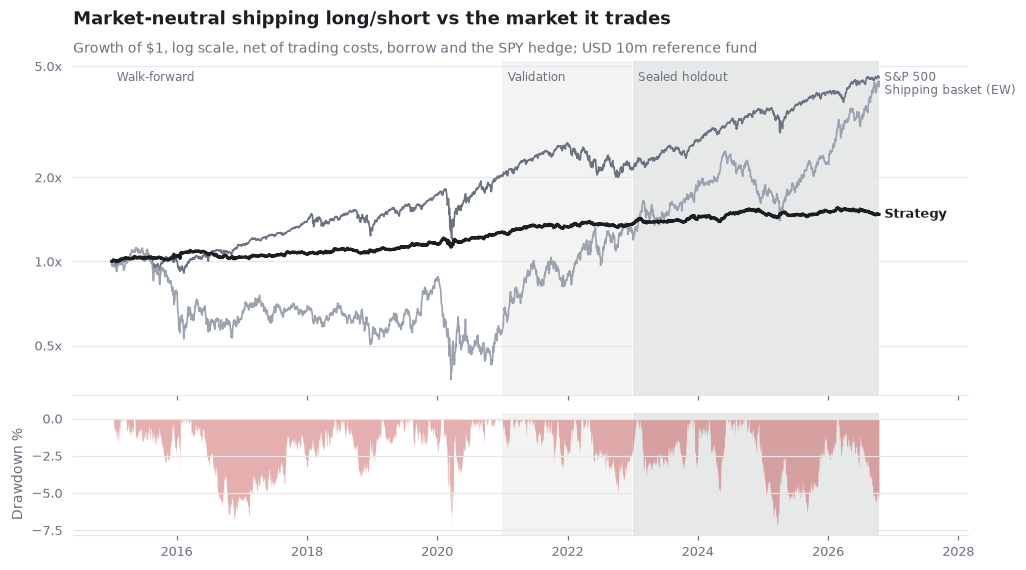

In [3]:
fig = charts.equity_curve(strat["strategy"], {"S&P 500": bench["SPY"], "Shipping basket (EW)": bench["EW shipping basket"]})
plt.show()

## Five findings

1. **Public freight data is priced within the week.** Segment equity baskets and their Baltic
   index move together contemporaneously; neither predicts the other a month out in dry bulk,
   with only a modest lag in tankers (project 02).
2. **Cheapness within a segment works; balance-sheet quality and freight timing do not, on their
   own.** Book-to-market inside each segment, and fading moves that are out of line with a
   stock's freight sensitivity, are the two signals that survive walk-forward testing (notebooks 01-04).
   A pre-registered hypothesis that balance-sheet strength pays only in falling freight markets
   was rejected and left rejected.
3. **The return is genuinely market-neutral** (beta near zero, low correlation to the shipping
   basket) and positive in the 2016 trough and the Red Sea disruption, but it gave back about 5%
   in the 2026 Hormuz crisis (notebooks 05, 07).
4. **Capacity is the binding constraint.** These stocks trade a few million dollars a day.
   Sharpe is roughly 0.6-0.8 up to USD 25m and dollar alpha plateaus below USD 1m a year (notebook 06).
5. **After correcting for the search, the public-data edge is not statistically distinguishable
   from luck.** That points to where an edge must come from: company-specific operating
   information that reaches the market late. FleetWatch (project 04) tracks ~1,000 named ships
   of 21 listed owners for exactly that, with every estimate committed to git before the
   companies report.

## The four projects

| Project | Question |
|---|---|
| [01 Data foundation](../../01-data-foundation) | Can you trust free shipping-equity data? |
| [02 Freight priced by Friday](../../02-freight-priced-by-friday) | Does public freight data predict shipping stocks? |
| [03 Market-neutral long/short](../../03-market-neutral-long-short) | Is there stock-selection alpha from public data? (this project) |
| [04 FleetWatch](../../04-fleetwatch) | Can ship-level tracking of each owner's fleet give an edge? |

Detail notebooks in this project: 01 signals, 02-04 the three sleeves, 05 portfolio and risk,
06 robustness, 07 stress windows.